# Baseline RoCoLe masked: mayoría, logística y Random Forest

Este cuaderno repite el baseline honesto del 04 sobre las mismas siete medidas del EDA (ExG, NGRDI y GLCM, sin VARI), pero calculadas solo dentro de la máscara COCO. Train aprende, val elige, test se mira al final. Después se puede comparar mentalmente con el baseline sin máscara (alrededor de 0.55–0.56) sin reabrir ese test.


## Semilla fija

**Entrada:** ninguna.

**Qué hacemos:** fijamos la semilla del proyecto para que el azar del bosque se pueda repetir.

**Salida:** seed.


In [1]:
# Entrada
# ninguna

# Qué hacemos
seed = 42

# Salida
seed


42

## Ruta de características enmascaradas

**Entrada:** ninguna.

**Qué hacemos:** localizamos la tabla featured con máscara COCO, relativa al repo.

**Salida:** features_path.


In [2]:
# Entrada
from pathlib import Path

# Qué hacemos
features_path = Path("../../data/featured/rocole/rgb_glcm_features_masked.csv")

# Salida
print("features_path:", features_path.resolve())
print("existe:", features_path.exists())
features_path


features_path: D:\Maestria\Documentos\Proyecto de innovación tecnologica en IA\Desarrollo\diagnostico-hojas-cafe\data\featured\rocole\rgb_glcm_features_masked.csv
existe: True


WindowsPath('../../data/featured/rocole/rgb_glcm_features_masked.csv')

## Cargar la tabla featured enmascarada

**Entrada:** features_path.

**Qué hacemos:** cargamos esa tabla. Si existe la columna error y trae valor, dejamos fuera esas filas (fallo de extracción) sin rehacer el split. Conservamos File, split y link_group.

**Salida:** leaf_features.


In [3]:
# Entrada
import pandas as pd

# Qué hacemos
leaf_features = pd.read_csv(features_path)
# Filas con error de extracción (si la columna existe y no está vacía)
if "error" in leaf_features.columns:
    error_text = leaf_features["error"].astype("string").fillna("").str.strip()
    n_before = len(leaf_features)
    leaf_features = leaf_features.loc[error_text == ""].copy()
    print("filas antes del filtro error:", n_before)
    print("filas después (sin error):", len(leaf_features))

# Salida
leaf_features.head()


filas antes del filtro error: 1481
filas después (sin error): 1481


,File,split,link_group,Binary.Label,Multiclass.Label,error,exg_mean,exg_std,ngrdi_mean,ngrdi_std,vari_mean,vari_std,glcm_contrast,glcm_homogeneity,glcm_energy
0,C1P1H1.jpg,train,74,healthy,healthy,NaN,0.466084,0.197243,0.250576,0.079053,0.348592,0.076514,0.684317,0.895943,0.381573
1,C1P2E2.jpg,train,84,unhealthy,rust_level_2,NaN,0.324993,0.094060,0.130550,0.068199,0.180603,0.094060,0.636574,0.897060,0.414018
2,C1P2H1.jpg,train,84,healthy,healthy,NaN,0.427245,0.191211,0.199764,0.056161,0.272501,0.049086,0.650484,0.886744,0.405814
3,C1P3E1.jpg,train,95,healthy,healthy,NaN,0.222965,0.062609,0.106283,0.021579,0.165645,0.029721,0.549393,0.927267,0.513788
4,C1P3E2.jpg,train,95,unhealthy,rust_level_2,NaN,0.237410,0.106820,0.062168,0.077000,0.085289,0.112395,0.660769,0.895654,0.415801


## Inspección rápida

**Entrada:** leaf_features.

**Qué hacemos:** miramos de un vistazo columnas y tamaño, para confirmar que llegó el featured con máscara.

**Salida:** ninguna (solo vista).


In [4]:
# Entrada
# leaf_features

# Qué hacemos
print("filas:", len(leaf_features))
print("columnas:", list(leaf_features.columns))

# Salida
leaf_features.info()


filas: 1481
columnas: ['File', 'split', 'link_group', 'Binary.Label', 'Multiclass.Label', 'error', 'exg_mean', 'exg_std', 'ngrdi_mean', 'ngrdi_std', 'vari_mean', 'vari_std', 'glcm_contrast', 'glcm_homogeneity', 'glcm_energy']
<class 'pandas.DataFrame'>
RangeIndex: 1481 entries, 0 to 1480
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   File              1481 non-null   str    
 1   split             1481 non-null   str    
 2   link_group        1481 non-null   int64  
 3   Binary.Label      1481 non-null   str    
 4   Multiclass.Label  1481 non-null   str    
 5   error             0 non-null      float64
 6   exg_mean          1481 non-null   float64
 7   exg_std           1481 non-null   float64
 8   ngrdi_mean        1481 non-null   float64
 9   ngrdi_std         1481 non-null   float64
 10  vari_mean         1481 non-null   float64
 11  vari_std          1481 non-null   float64
 12  glcm_contrast  

## Conteos por etiqueta

**Entrada:** leaf_features.

**Qué hacemos:** contamos cuántas hojas hay por Binary.Label en toda la tabla (sana frente a afectada).

**Salida:** label_counts.


In [5]:
# Entrada
# leaf_features

# Qué hacemos
label_counts = leaf_features["Binary.Label"].value_counts()

# Salida
label_counts


Binary.Label
healthy      758
unhealthy    723
Name: count, dtype: int64

## Conteos por split

**Entrada:** leaf_features.

**Qué hacemos:** contamos cuántas hojas caen en train, val y test según la columna split ya guardada.

**Salida:** split_counts.


In [6]:
# Entrada
# leaf_features

# Qué hacemos
split_counts = leaf_features["split"].value_counts()

# Salida
split_counts


split
train    1037
test      226
val       218
Name: count, dtype: int64

## Siete medidas (sin VARI)

**Entrada:** ninguna.

**Qué hacemos:** listamos las siete medidas: medias y desviaciones de ExG y NGRDI, más contraste, homogeneidad y energía GLCM. Sin VARI.

**Salida:** feature_columns.


In [7]:
# Entrada
# ninguna

# Qué hacemos
feature_columns = [
    "exg_mean",
    "exg_std",
    "ngrdi_mean",
    "ngrdi_std",
    "glcm_contrast",
    "glcm_homogeneity",
    "glcm_energy",
]

# Salida
feature_columns


['exg_mean',
 'exg_std',
 'ngrdi_mean',
 'ngrdi_std',
 'glcm_contrast',
 'glcm_homogeneity',
 'glcm_energy']

## Hojas de aprender

**Entrada:** leaf_features.

**Qué hacemos:** apartamos las hojas de aprender con split igual a train.

**Salida:** train_leaves.


In [8]:
# Entrada
# leaf_features

# Qué hacemos
train_leaves = leaf_features.loc[leaf_features["split"] == "train"].copy()

# Salida
print("train:", len(train_leaves))
train_leaves.head()


train: 1037


,File,split,link_group,Binary.Label,Multiclass.Label,error,exg_mean,exg_std,ngrdi_mean,ngrdi_std,vari_mean,vari_std,glcm_contrast,glcm_homogeneity,glcm_energy
0,C1P1H1.jpg,train,74,healthy,healthy,NaN,0.466084,0.197243,0.250576,0.079053,0.348592,0.076514,0.684317,0.895943,0.381573
1,C1P2E2.jpg,train,84,unhealthy,rust_level_2,NaN,0.324993,0.094060,0.130550,0.068199,0.180603,0.094060,0.636574,0.897060,0.414018
2,C1P2H1.jpg,train,84,healthy,healthy,NaN,0.427245,0.191211,0.199764,0.056161,0.272501,0.049086,0.650484,0.886744,0.405814
3,C1P3E1.jpg,train,95,healthy,healthy,NaN,0.222965,0.062609,0.106283,0.021579,0.165645,0.029721,0.549393,0.927267,0.513788
4,C1P3E2.jpg,train,95,unhealthy,rust_level_2,NaN,0.237410,0.106820,0.062168,0.077000,0.085289,0.112395,0.660769,0.895654,0.415801


## Hojas de validación

**Entrada:** leaf_features.

**Qué hacemos:** apartamos las hojas de validación con split igual a val.

**Salida:** val_leaves.


In [9]:
# Entrada
# leaf_features

# Qué hacemos
val_leaves = leaf_features.loc[leaf_features["split"] == "val"].copy()

# Salida
print("val:", len(val_leaves))
val_leaves.head()


val: 218


,File,split,link_group,Binary.Label,Multiclass.Label,error,exg_mean,exg_std,ngrdi_mean,ngrdi_std,vari_mean,vari_std,glcm_contrast,glcm_homogeneity,glcm_energy
17,C1P8E1.jpg,val,107,healthy,healthy,NaN,0.249345,0.060095,0.134210,0.028443,0.210544,0.040120,0.433850,0.919154,0.443882
18,C1P8H1.jpg,val,107,healthy,healthy,NaN,0.674827,0.238645,0.354390,0.096486,0.451937,0.088812,0.865084,0.884578,0.351502
65,C1P32E2.jpg,val,98,unhealthy,rust_level_1,NaN,0.322202,0.080005,0.149958,0.044135,0.214389,0.058643,0.638661,0.894372,0.359549
67,C1P32H2.jpg,val,98,unhealthy,rust_level_1,NaN,0.537461,0.189366,0.260906,0.095505,0.336990,0.113097,0.820624,0.879710,0.370061
116,C2P12E1.jpg,val,112,healthy,healthy,NaN,0.319254,0.227025,0.094601,0.073056,0.115038,0.080450,0.432778,0.965875,0.479436


## Hojas de prueba (guardadas)

**Entrada:** leaf_features.

**Qué hacemos:** apartamos las hojas de prueba con split igual a test y las dejamos guardadas hasta el final.

**Salida:** test_leaves.


In [10]:
# Entrada
# leaf_features

# Qué hacemos
test_leaves = leaf_features.loc[leaf_features["split"] == "test"].copy()

# Salida
print("test:", len(test_leaves))
test_leaves.head()


test: 226


,File,split,link_group,Binary.Label,Multiclass.Label,error,exg_mean,exg_std,ngrdi_mean,ngrdi_std,vari_mean,vari_std,glcm_contrast,glcm_homogeneity,glcm_energy
10,C1P5E1.jpg,test,104,healthy,healthy,NaN,0.248237,0.043188,0.135763,0.019674,0.213951,0.029531,0.556096,0.924134,0.499425
11,C1P5H1.jpg,test,104,healthy,healthy,NaN,0.554682,0.210872,0.307915,0.088875,0.418594,0.084991,0.857413,0.891542,0.354807
38,C1P24E2.jpg,test,89,unhealthy,rust_level_2,NaN,0.233868,0.117219,0.070648,0.074822,0.100594,0.105818,0.649809,0.852549,0.345053
39,C1P24H2.jpg,test,89,unhealthy,rust_level_2,NaN,0.301251,0.148002,0.128988,0.083274,0.184340,0.114539,0.603894,0.898805,0.358850
63,C1P31H2.jpg,test,97,unhealthy,rust_level_1,NaN,0.511388,0.161097,0.221980,0.069247,0.280197,0.078694,0.634208,0.906141,0.379058


## Desbalance en train

**Entrada:** train_leaves.

**Qué hacemos:** contamos sanas y afectadas solo en train, para ver el desbalance que aprenderá el modelo.

**Salida:** train_label_counts.


In [11]:
# Entrada
# train_leaves

# Qué hacemos
train_label_counts = train_leaves["Binary.Label"].value_counts()

# Salida
train_label_counts


Binary.Label
healthy      530
unhealthy    507
Name: count, dtype: int64

## Etiquetas en val

**Entrada:** val_leaves.

**Qué hacemos:** contamos sanas y afectadas en val.

**Salida:** val_label_counts.


In [12]:
# Entrada
# val_leaves

# Qué hacemos
val_label_counts = val_leaves["Binary.Label"].value_counts()

# Salida
val_label_counts


Binary.Label
healthy      113
unhealthy    105
Name: count, dtype: int64

## Etiquetas en test (solo inventario)

**Entrada:** test_leaves.

**Qué hacemos:** contamos sanas y afectadas en test (solo inventario; aún no medimos acierto).

**Salida:** test_label_counts.


In [13]:
# Entrada
# test_leaves

# Qué hacemos
test_label_counts = test_leaves["Binary.Label"].value_counts()

# Salida
test_label_counts


Binary.Label
healthy      115
unhealthy    111
Name: count, dtype: int64

## Medidas de train

**Entrada:** train_leaves, feature_columns.

**Qué hacemos:** sacamos de train la matriz de las siete medidas, manteniendo el mismo orden de filas que las etiquetas.

**Salida:** train_features.


In [14]:
# Entrada
# train_leaves, feature_columns

# Qué hacemos
train_features = train_leaves[feature_columns].copy()

# Salida
print(train_features.shape)
train_features.head()


(1037, 7)


,exg_mean,exg_std,ngrdi_mean,ngrdi_std,glcm_contrast,glcm_homogeneity,glcm_energy
0,0.466084,0.197243,0.250576,0.079053,0.684317,0.895943,0.381573
1,0.324993,0.094060,0.130550,0.068199,0.636574,0.897060,0.414018
2,0.427245,0.191211,0.199764,0.056161,0.650484,0.886744,0.405814
3,0.222965,0.062609,0.106283,0.021579,0.549393,0.927267,0.513788
4,0.237410,0.106820,0.062168,0.077000,0.660769,0.895654,0.415801


## Etiquetas de train

**Entrada:** train_leaves.

**Qué hacemos:** sacamos de train la etiqueta Binary.Label, en el mismo orden de filas.

**Salida:** train_labels.


In [15]:
# Entrada
# train_leaves

# Qué hacemos
train_labels = train_leaves["Binary.Label"].copy()

# Salida
print(train_labels.shape)
train_labels.head()


(1037,)


0      healthy
1    unhealthy
2      healthy
3      healthy
4    unhealthy
Name: Binary.Label, dtype: str

## Medidas de val

**Entrada:** val_leaves, feature_columns.

**Qué hacemos:** sacamos de val las siete medidas.

**Salida:** val_features.


In [16]:
# Entrada
# val_leaves, feature_columns

# Qué hacemos
val_features = val_leaves[feature_columns].copy()

# Salida
print(val_features.shape)
val_features.head()


(218, 7)


,exg_mean,exg_std,ngrdi_mean,ngrdi_std,glcm_contrast,glcm_homogeneity,glcm_energy
17,0.249345,0.060095,0.134210,0.028443,0.433850,0.919154,0.443882
18,0.674827,0.238645,0.354390,0.096486,0.865084,0.884578,0.351502
65,0.322202,0.080005,0.149958,0.044135,0.638661,0.894372,0.359549
67,0.537461,0.189366,0.260906,0.095505,0.820624,0.879710,0.370061
116,0.319254,0.227025,0.094601,0.073056,0.432778,0.965875,0.479436


## Etiquetas de val

**Entrada:** val_leaves.

**Qué hacemos:** sacamos de val la etiqueta Binary.Label.

**Salida:** val_labels.


In [17]:
# Entrada
# val_leaves

# Qué hacemos
val_labels = val_leaves["Binary.Label"].copy()

# Salida
print(val_labels.shape)
val_labels.head()


(218,)


17       healthy
18       healthy
65     unhealthy
67     unhealthy
116      healthy
Name: Binary.Label, dtype: str

## Medidas de test (sin mirar acierto)

**Entrada:** test_leaves, feature_columns.

**Qué hacemos:** sacamos de test las siete medidas y las dejamos sin mirar acierto.

**Salida:** test_features.


In [18]:
# Entrada
# test_leaves, feature_columns

# Qué hacemos
test_features = test_leaves[feature_columns].copy()

# Salida
print(test_features.shape)
test_features.head()


(226, 7)


,exg_mean,exg_std,ngrdi_mean,ngrdi_std,glcm_contrast,glcm_homogeneity,glcm_energy
10,0.248237,0.043188,0.135763,0.019674,0.556096,0.924134,0.499425
11,0.554682,0.210872,0.307915,0.088875,0.857413,0.891542,0.354807
38,0.233868,0.117219,0.070648,0.074822,0.649809,0.852549,0.345053
39,0.301251,0.148002,0.128988,0.083274,0.603894,0.898805,0.358850
63,0.511388,0.161097,0.221980,0.069247,0.634208,0.906141,0.379058


## Etiquetas de test

**Entrada:** test_leaves.

**Qué hacemos:** sacamos de test la etiqueta Binary.Label.

**Salida:** test_labels.


In [19]:
# Entrada
# test_leaves

# Qué hacemos
test_labels = test_leaves["Binary.Label"].copy()

# Salida
print(test_labels.shape)
test_labels.head()


(226,)

10      healthy
11      healthy
38    unhealthy
39    unhealthy
63    unhealthy
Name: Binary.Label, dtype: str

## Clasificador de mayoría

**Entrada:** train_features, train_labels.

**Qué hacemos:** como piso tonto, un clasificador de mayoría: siempre predice la clase más frecuente de train.

**Salida:** majority_model.


In [20]:
# Entrada
from sklearn.dummy import DummyClassifier

# Qué hacemos
majority_model = DummyClassifier(strategy="most_frequent")
majority_model.fit(train_features, train_labels)

# Salida
majority_model


,"strategy strategy: {""most_frequent"", ""prior"", ""stratified"", ""uniform"", ""constant""}, default=""prior""Strategy to use to generate predictions.* ""most_frequent"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit`. The `predict_proba` method returns the matching one-hot encoded vector.* ""prior"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit` (like ""most_frequent""). ``predict_proba`` always returns the empirical class distribution of `y` also known as the empirical class prior distribution.* ""stratified"": the `predict_proba` method randomly samples one-hot vectors from a multinomial distribution parametrized by the empirical class prior probabilities. The `predict` method returns the class label which got probability one in the one-hot vector of `predict_proba`. Each sampled row of both methods is therefore independent and identically distributed.* ""uniform"": generates predictions uniformly at random from the list of unique classes observed in `y`, i.e. each class has equal probability.* ""constant"": always predicts a constant label that is provided by the user. This is useful for metrics that evaluate a non-majority class. .. versionchanged:: 0.24 The default value of `strategy` has changed to ""prior"" in version 0.24.",'most_frequent'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness to generate the predictions when``strategy='stratified'`` or ``strategy='uniform'``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"constant constant: int or str or array-like of shape (n_outputs,), default=NoneThe explicit constant as predicted by the ""constant"" strategy. Thisparameter is useful only for the ""constant"" strategy.",None
Name,Type,Value
"class_prior_ class_prior_: ndarray of shape (n_classes,) or list of such arraysFrequency of each class observed in `y`. For multioutput classificationproblems, this is computed independently for each output.","ndarray[float64](2,)","[0.51,0.49]"
"classes_ classes_: ndarray of shape (n_classes,) or list of such arraysUnique class labels observed in `y`. For multi-output classificationproblems, this attribute is a list of arrays as each output has anindependent set of possible classes.","ndarray[object](2,)","['healthy','unhealthy']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X` hasfeature names that are all strings.","ndarray[object](7,)","['exg_mean','exg_std','ngrdi_mean',...,'glcm_contrast','glcm_homogeneity', 'glcm_energy']"
n_classes_ n_classes_: int or list of intNumber of label for each output.,int,2
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`.,int,7
n_outputs_ n_outputs_: intNumber of outputs.,int,1
sparse_output_ sparse_output_: boolTrue if the array returned from predict is to be in sparse CSC format.Is automatically set to True if the input `y` is passed in sparseformat.,bool,False


## Mayoría en val

**Entrada:** majority_model, val_features, val_labels.

**Qué hacemos:** medimos ese piso en val (f1_macro y un reporte corto) para saber qué es no saber nada.

**Salida:** majority_val_metrics.


In [21]:
# Entrada
from sklearn.metrics import classification_report, f1_score

# Qué hacemos
majority_val_predictions = majority_model.predict(val_features)
majority_val_f1 = f1_score(val_labels, majority_val_predictions, average="macro")
majority_val_report = classification_report(val_labels, majority_val_predictions)
majority_val_metrics = {
    "f1_macro": majority_val_f1,
    "report": majority_val_report,
}

# Salida
print("f1_macro val (mayoría):", majority_val_metrics["f1_macro"])
print(majority_val_metrics["report"])
majority_val_metrics


f1_macro val (mayoría): 0.3413897280966767
              precision    recall  f1-score   support

     healthy       0.52      1.00      0.68       113
   unhealthy       0.00      0.00      0.00       105

    accuracy                           0.52       218
   macro avg       0.26      0.50      0.34       218
weighted avg       0.27      0.52      0.35       218



D:\Maestria\Documentos\Proyecto de innovación tecnologica en IA\Desarrollo\diagnostico-hojas-cafe\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
D:\Maestria\Documentos\Proyecto de innovación tecnologica en IA\Desarrollo\diagnostico-hojas-cafe\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
D:\Maestria\Documentos\Proyecto de innovación tecnologica en IA\Desarrollo\diagnostico-hojas-cafe\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precisi

{'f1_macro': 0.3413897280966767,
 'report': '              precision    recall  f1-score   support\n\n     healthy       0.52      1.00      0.68       113\n   unhealthy       0.00      0.00      0.00       105\n\n    accuracy                           0.52       218\n   macro avg       0.26      0.50      0.34       218\nweighted avg       0.27      0.52      0.35       218\n'}

## Escalador (solo train)

**Entrada:** train_features.

**Qué hacemos:** ajustamos un escalador solo con las medidas de train (la logística es sensible a la escala).

**Salida:** feature_scaler.


In [22]:
# Entrada
from sklearn.preprocessing import StandardScaler

# Qué hacemos
feature_scaler = StandardScaler()
feature_scaler.fit(train_features)

# Salida
feature_scaler


StandardScaler()

## Train escalado

**Entrada:** feature_scaler, train_features.

**Qué hacemos:** transformamos las medidas de train con ese escalador ya ajustado.

**Salida:** train_features_scaled.


In [23]:
# Entrada
# feature_scaler, train_features

# Qué hacemos
train_features_scaled = feature_scaler.transform(train_features)

# Salida
print(train_features_scaled.shape)
train_features_scaled


(1037, 7)


array([[ 0.0859831 ,  0.06155112,  0.64374191, ..., -0.09746288,
        -0.54105809, -0.34927338],
       [-0.53794071, -1.06996785, -0.48360402, ..., -0.23255003,
        -0.50795393,  0.07424347],
       [-0.08576967, -0.00459443,  0.16648974, ..., -0.19319084,
        -0.81364196, -0.0328529 ],
       ...,
       [ 0.82871269,  0.0130189 ,  0.74276544, ..., -0.77295449,
         1.46447744,  0.18444631],
       [-0.23642957, -0.32827746, -0.23694192, ...,  0.60460305,
        -0.87534931, -0.15624526],
       [-0.25722629, -0.20074905, -0.46517254, ...,  0.50753139,
        -0.00814869, -0.1050303 ]], shape=(1037, 7))

## Val escalado

**Entrada:** feature_scaler, val_features.

**Qué hacemos:** transformamos las medidas de val con el mismo escalador de train.

**Salida:** val_features_scaled.


In [24]:
# Entrada
# feature_scaler, val_features

# Qué hacemos
val_features_scaled = feature_scaler.transform(val_features)

# Salida
print(val_features_scaled.shape)
val_features_scaled


(218, 7)


array([[-0.87247018, -1.44243732, -0.44922163, ..., -0.80614991,
         0.146731  ,  0.46406903],
       [ 1.0090749 ,  0.51557527,  1.61880985, ...,  0.41401013,
        -0.87780243, -0.74180533],
       [-0.55028342, -1.22409837, -0.30131174, ..., -0.22664401,
        -0.58758536, -0.63676781],
       ...,
       [-1.0542486 , -1.64959817, -0.5628609 , ..., -0.50085145,
         0.92590533,  0.9283415 ],
       [ 0.07563133, -0.67376064,  0.63238157, ..., -0.3457389 ,
         0.06698197, -0.2927296 ],
       [-0.84806667, -1.0274876 , -0.48123116, ..., -0.35183129,
         0.94884087, -0.01689153]], shape=(218, 7))

## Rejilla corta de C (logística)

**Entrada:** train_features_scaled, train_labels, val_features_scaled, val_labels, seed.

**Qué hacemos:** probamos en val unos pocos valores de C para la logística (rejilla corta 0.01, 0.1, 1, 10, 100), con class_weight balanced.

**Salida:** logistic_val_scores.


In [25]:
# Entrada
from sklearn.linear_model import LogisticRegression

logistic_C_grid = [0.01, 0.1, 1, 10, 100]

# Qué hacemos
logistic_val_scores = []
for C in logistic_C_grid:
    candidate = LogisticRegression(
        C=C,
        class_weight="balanced",
        max_iter=1000,
        random_state=seed,
    )
    candidate.fit(train_features_scaled, train_labels)
    val_pred = candidate.predict(val_features_scaled)
    score = f1_score(val_labels, val_pred, average="macro")
    logistic_val_scores.append({"C": C, "f1_macro": score})

# Salida
logistic_val_scores


[{'C': 0.01, 'f1_macro': 0.7110030932390632},
 {'C': 0.1, 'f1_macro': 0.7155005472762481},
 {'C': 1, 'f1_macro': 0.7109544354414395},
 {'C': 10, 'f1_macro': 0.7155005472762481},
 {'C': 100, 'f1_macro': 0.7155005472762481}]

## Mejor C en val

**Entrada:** logistic_val_scores.

**Qué hacemos:** nos quedamos con el C que mejor f1_macro dio en val.

**Salida:** best_logistic_C.


In [26]:
# Entrada
# logistic_val_scores

# Qué hacemos
best_logistic_row = max(logistic_val_scores, key=lambda row: row["f1_macro"])
best_logistic_C = best_logistic_row["C"]

# Salida
print("mejor C:", best_logistic_C, "f1_macro val:", best_logistic_row["f1_macro"])
best_logistic_C


mejor C: 0.1 f1_macro val: 0.7155005472762481


0.1

## Logística final (train)

**Entrada:** train_features_scaled, train_labels, best_logistic_C, seed.

**Qué hacemos:** reajustamos la logística final con ese C, solo sobre train escalado.

**Salida:** logistic_model.


In [27]:
# Entrada
# train_features_scaled, train_labels, best_logistic_C

# Qué hacemos
logistic_model = LogisticRegression(
    C=best_logistic_C,
    class_weight="balanced",
    max_iter=1000,
    random_state=seed,
)
logistic_model.fit(train_features_scaled, train_labels)

# Salida
logistic_model


,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",0.1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to u

## Logística en val

**Entrada:** logistic_model, val_features_scaled, val_labels.

**Qué hacemos:** guardamos las métricas de la logística en val (f1_macro y reporte).

**Salida:** logistic_val_metrics.


In [28]:
# Entrada
# logistic_model, val_features_scaled, val_labels

# Qué hacemos
logistic_val_predictions = logistic_model.predict(val_features_scaled)
logistic_val_f1 = f1_score(val_labels, logistic_val_predictions, average="macro")
logistic_val_report = classification_report(val_labels, logistic_val_predictions)
logistic_val_metrics = {
    "f1_macro": logistic_val_f1,
    "report": logistic_val_report,
}

# Salida
print("f1_macro val (logística):", logistic_val_metrics["f1_macro"])
print(logistic_val_metrics["report"])
logistic_val_metrics


f1_macro val (logística): 0.7155005472762481
              precision    recall  f1-score   support

     healthy       0.73      0.71      0.72       113
   unhealthy       0.70      0.72      0.71       105

    accuracy                           0.72       218
   macro avg       0.72      0.72      0.72       218
weighted avg       0.72      0.72      0.72       218



{'f1_macro': 0.7155005472762481,
 'report': '              precision    recall  f1-score   support\n\n     healthy       0.73      0.71      0.72       113\n   unhealthy       0.70      0.72      0.71       105\n\n    accuracy                           0.72       218\n   macro avg       0.72      0.72      0.72       218\nweighted avg       0.72      0.72      0.72       218\n'}

## Rejilla corta del bosque

**Entrada:** seed.

**Qué hacemos:** definimos una rejilla corta de n_estimators (100, 200) y max_depth (None, 5, 10) para el bosque, con random_state igual a seed.

**Salida:** rf_param_grid.


In [29]:
# Entrada
# seed

# Qué hacemos
rf_param_grid = [
    {"n_estimators": n_estimators, "max_depth": max_depth, "random_state": seed}
    for n_estimators in [100, 200]
    for max_depth in [None, 5, 10]
]

# Salida
rf_param_grid


[{'n_estimators': 100, 'max_depth': None, 'random_state': 42},
 {'n_estimators': 100, 'max_depth': 5, 'random_state': 42},
 {'n_estimators': 100, 'max_depth': 10, 'random_state': 42},
 {'n_estimators': 200, 'max_depth': None, 'random_state': 42},
 {'n_estimators': 200, 'max_depth': 5, 'random_state': 42},
 {'n_estimators': 200, 'max_depth': 10, 'random_state': 42}]

## Probar el bosque en val

**Entrada:** train_features, train_labels, val_features, val_labels, rf_param_grid.

**Qué hacemos:** probamos cada par de la rejilla en val midiendo f1_macro (bosque sobre medidas sin escalar; el RF no necesita el escalador), con class_weight balanced.

**Salida:** rf_val_scores.


In [30]:
# Entrada
from sklearn.ensemble import RandomForestClassifier

# Qué hacemos
rf_val_scores = []
for params in rf_param_grid:
    candidate = RandomForestClassifier(
        n_estimators=params["n_estimators"],
        max_depth=params["max_depth"],
        class_weight="balanced",
        random_state=params["random_state"],
    )
    candidate.fit(train_features, train_labels)
    val_pred = candidate.predict(val_features)
    score = f1_score(val_labels, val_pred, average="macro")
    rf_val_scores.append(
        {
            "n_estimators": params["n_estimators"],
            "max_depth": params["max_depth"],
            "f1_macro": score,
        }
    )

# Salida
rf_val_scores


[{'n_estimators': 100, 'max_depth': None, 'f1_macro': 0.7201304851099652},
 {'n_estimators': 100, 'max_depth': 5, 'f1_macro': 0.7149966261808367},
 {'n_estimators': 100, 'max_depth': 10, 'f1_macro': 0.7384825844470168},
 {'n_estimators': 200, 'max_depth': None, 'f1_macro': 0.7109544354414395},
 {'n_estimators': 200, 'max_depth': 5, 'f1_macro': 0.7198946814112691},
 {'n_estimators': 200, 'max_depth': 10, 'f1_macro': 0.7431192660550459}]

## Mejores hiperparámetros del bosque

**Entrada:** rf_val_scores.

**Qué hacemos:** elegimos el par n_estimators y max_depth con mejor f1_macro en val.

**Salida:** best_rf_params.


In [31]:
# Entrada
# rf_val_scores

# Qué hacemos
best_rf_row = max(rf_val_scores, key=lambda row: row["f1_macro"])
best_rf_params = {
    "n_estimators": best_rf_row["n_estimators"],
    "max_depth": best_rf_row["max_depth"],
}

# Salida
print("mejores params:", best_rf_params, "f1_macro val:", best_rf_row["f1_macro"])
best_rf_params


mejores params: {'n_estimators': 200, 'max_depth': 10} f1_macro val: 0.7431192660550459


{'n_estimators': 200, 'max_depth': 10}

## Bosque final (train)

**Entrada:** train_features, train_labels, best_rf_params, seed.

**Qué hacemos:** reajustamos el bosque final solo con train y esos hiperparámetros.

**Salida:** random_forest_model.


In [32]:
# Entrada
# train_features, train_labels, best_rf_params, seed

# Qué hacemos
random_forest_model = RandomForestClassifier(
    n_estimators=best_rf_params["n_estimators"],
    max_depth=best_rf_params["max_depth"],
    class_weight="balanced",
    random_state=seed,
)
random_forest_model.fit(train_features, train_labels)

# Salida
random_forest_model


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 

## Bosque en val

**Entrada:** random_forest_model, val_features, val_labels.

**Qué hacemos:** guardamos las métricas del bosque en val.

**Salida:** rf_val_metrics.


In [33]:
# Entrada
# random_forest_model, val_features, val_labels

# Qué hacemos
rf_val_predictions = random_forest_model.predict(val_features)
rf_val_f1 = f1_score(val_labels, rf_val_predictions, average="macro")
rf_val_report = classification_report(val_labels, rf_val_predictions)
rf_val_metrics = {
    "f1_macro": rf_val_f1,
    "report": rf_val_report,
}

# Salida
print("f1_macro val (bosque):", rf_val_metrics["f1_macro"])
print(rf_val_metrics["report"])
rf_val_metrics


f1_macro val (bosque): 0.7431192660550459
              precision    recall  f1-score   support

     healthy       0.77      0.72      0.74       113
   unhealthy       0.72      0.77      0.74       105

    accuracy                           0.74       218
   macro avg       0.74      0.74      0.74       218
weighted avg       0.75      0.74      0.74       218



{'f1_macro': 0.7431192660550459,
 'report': '              precision    recall  f1-score   support\n\n     healthy       0.77      0.72      0.74       113\n   unhealthy       0.72      0.77      0.74       105\n\n    accuracy                           0.74       218\n   macro avg       0.74      0.74      0.74       218\nweighted avg       0.75      0.74      0.74       218\n'}

## Comparación en val

**Entrada:** majority_val_metrics, logistic_val_metrics, rf_val_metrics.

**Qué hacemos:** comparamos en una tablita pequeña el f1_macro de val: mayoría, logística y bosque. Solo para leer quién ganó la validación.

**Salida:** val_comparison.


In [34]:
# Entrada
# majority_val_metrics, logistic_val_metrics, rf_val_metrics

# Qué hacemos
val_comparison = pd.DataFrame(
    [
        {"modelo": "mayoria", "f1_macro_val": majority_val_metrics["f1_macro"]},
        {"modelo": "logistica", "f1_macro_val": logistic_val_metrics["f1_macro"]},
        {"modelo": "random_forest", "f1_macro_val": rf_val_metrics["f1_macro"]},
    ]
)

# Salida
val_comparison


,modelo,f1_macro_val
0,mayoria,0.341390
1,logistica,0.715501
2,random_forest,0.743119


## Test escalado

**Entrada:** feature_scaler, test_features.

**Qué hacemos:** ahora sí: escalamos test con el escalador de train (transform, sin refit).

**Salida:** test_features_scaled.


In [35]:
# Entrada
# feature_scaler, test_features

# Qué hacemos
test_features_scaled = feature_scaler.transform(test_features)

# Salida
print(test_features_scaled.shape)
test_features_scaled


(226, 7)


array([[-0.87736685, -1.62784068, -0.4346416 , ..., -0.46025827,
         0.29431075,  1.18908703],
       [ 0.47777654,  0.2110142 ,  1.18229462, ...,  0.39230498,
        -0.67146779, -0.69866749],
       [-0.94091139, -0.81600931, -1.04622732, ..., -0.19510096,
        -1.82689789, -0.82598198],
       ...,
       [ 0.45535822,  0.2035344 ,  0.57193409, ..., -0.60804809,
         0.53768197,  1.54367451],
       [ 0.08237932, -1.13713129,  0.62782886, ..., -0.95089802,
         0.96458539,  0.93480414],
       [ 2.69045745,  1.40718135,  2.46210786, ...,  0.12561046,
        -0.87159005, -1.47751788]], shape=(226, 7))

## Predicción logística en test

**Entrada:** logistic_model, test_features_scaled.

**Qué hacemos:** predicción única de la logística en test.

**Salida:** logistic_test_predictions.


In [36]:
# Entrada
# logistic_model, test_features_scaled

# Qué hacemos
logistic_test_predictions = logistic_model.predict(test_features_scaled)

# Salida
logistic_test_predictions


array(['healthy', 'healthy', 'unhealthy', 'unhealthy', 'healthy',
       'healthy', 'unhealthy', 'healthy', 'unhealthy', 'unhealthy',
       'unhealthy', 'unhealthy', 'healthy', 'unhealthy', 'healthy',
       'healthy', 'healthy', 'unhealthy', 'healthy', 'healthy',
       'unhealthy', 'unhealthy', 'healthy', 'healthy', 'unhealthy',
       'healthy', 'unhealthy', 'healthy', 'healthy', 'unhealthy',
       'healthy', 'unhealthy', 'healthy', 'healthy', 'healthy', 'healthy',
       'unhealthy', 'healthy', 'healthy', 'unhealthy', 'healthy',
       'healthy', 'healthy', 'unhealthy', 'healthy', 'unhealthy',
       'healthy', 'unhealthy', 'unhealthy', 'unhealthy', 'unhealthy',
       'unhealthy', 'unhealthy', 'healthy', 'healthy', 'healthy',
       'healthy', 'healthy', 'healthy', 'unhealthy', 'unhealthy',
       'unhealthy', 'unhealthy', 'unhealthy', 'unhealthy', 'healthy',
       'unhealthy', 'healthy', 'unhealthy', 'healthy', 'healthy',
       'healthy', 'healthy', 'unhealthy', 'unhealthy', 

## Métricas de logística en test

**Entrada:** test_labels, logistic_test_predictions.

**Qué hacemos:** reporte y matriz de confusión de la logística en test (una sola vez).

**Salida:** logistic_test_metrics.


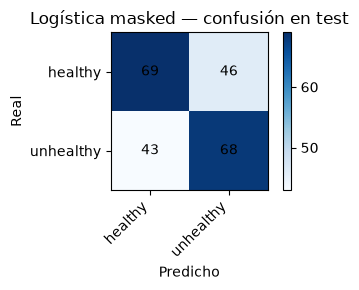

f1_macro test (logística): 0.6061869799314733
              precision    recall  f1-score   support

     healthy       0.62      0.60      0.61       115
   unhealthy       0.60      0.61      0.60       111

    accuracy                           0.61       226
   macro avg       0.61      0.61      0.61       226
weighted avg       0.61      0.61      0.61       226

matriz de confusión:
 [[69 46]
 [43 68]]


{'f1_macro': 0.6061869799314733,
 'report': '              precision    recall  f1-score   support\n\n     healthy       0.62      0.60      0.61       115\n   unhealthy       0.60      0.61      0.60       111\n\n    accuracy                           0.61       226\n   macro avg       0.61      0.61      0.61       226\nweighted avg       0.61      0.61      0.61       226\n',
 'confusion_matrix': array([[69, 46],
        [43, 68]])}

In [37]:
# Entrada
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

# Qué hacemos
logistic_test_f1 = f1_score(test_labels, logistic_test_predictions, average="macro")
logistic_test_report = classification_report(test_labels, logistic_test_predictions)
logistic_test_cm = confusion_matrix(test_labels, logistic_test_predictions)
logistic_test_metrics = {
    "f1_macro": logistic_test_f1,
    "report": logistic_test_report,
    "confusion_matrix": logistic_test_cm,
}

fig, ax = plt.subplots(figsize=(4, 3))
im = ax.imshow(logistic_test_cm, cmap="Blues")
ax.set_title("Logística masked — confusión en test")
ax.set_xlabel("Predicho")
ax.set_ylabel("Real")
labels = sorted(test_labels.unique())
ax.set_xticks(range(len(labels)))
ax.set_yticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=45, ha="right")
ax.set_yticklabels(labels)
for i in range(logistic_test_cm.shape[0]):
    for j in range(logistic_test_cm.shape[1]):
        ax.text(j, i, int(logistic_test_cm[i, j]), ha="center", va="center")
fig.colorbar(im, ax=ax, fraction=0.046)
fig.tight_layout()
plt.show()

# Salida
print("f1_macro test (logística):", logistic_test_metrics["f1_macro"])
print(logistic_test_metrics["report"])
print("matriz de confusión:\n", logistic_test_metrics["confusion_matrix"])
logistic_test_metrics


## Predicción del bosque en test

**Entrada:** random_forest_model, test_features.

**Qué hacemos:** predicción única del bosque en test.

**Salida:** rf_test_predictions.


In [38]:
# Entrada
# random_forest_model, test_features

# Qué hacemos
rf_test_predictions = random_forest_model.predict(test_features)

# Salida
rf_test_predictions


array(['healthy', 'healthy', 'unhealthy', 'unhealthy', 'unhealthy',
       'healthy', 'unhealthy', 'healthy', 'unhealthy', 'unhealthy',
       'unhealthy', 'unhealthy', 'healthy', 'unhealthy', 'healthy',
       'healthy', 'unhealthy', 'unhealthy', 'healthy', 'healthy',
       'healthy', 'healthy', 'healthy', 'healthy', 'unhealthy', 'healthy',
       'unhealthy', 'healthy', 'healthy', 'unhealthy', 'healthy',
       'healthy', 'healthy', 'unhealthy', 'healthy', 'healthy',
       'unhealthy', 'unhealthy', 'healthy', 'unhealthy', 'healthy',
       'healthy', 'healthy', 'unhealthy', 'healthy', 'unhealthy',
       'healthy', 'unhealthy', 'unhealthy', 'unhealthy', 'unhealthy',
       'unhealthy', 'unhealthy', 'healthy', 'healthy', 'healthy',
       'healthy', 'healthy', 'healthy', 'unhealthy', 'unhealthy',
       'unhealthy', 'healthy', 'unhealthy', 'healthy', 'healthy',
       'unhealthy', 'healthy', 'unhealthy', 'healthy', 'healthy',
       'healthy', 'healthy', 'unhealthy', 'unhealthy', 'h

## Métricas del bosque en test

**Entrada:** test_labels, rf_test_predictions.

**Qué hacemos:** reporte y matriz de confusión del bosque en test (una sola vez).

**Salida:** rf_test_metrics.


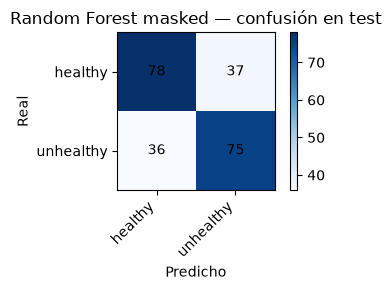

f1_macro test (bosque): 0.6769342236669473
              precision    recall  f1-score   support

     healthy       0.68      0.68      0.68       115
   unhealthy       0.67      0.68      0.67       111

    accuracy                           0.68       226
   macro avg       0.68      0.68      0.68       226
weighted avg       0.68      0.68      0.68       226

matriz de confusión:
 [[78 37]
 [36 75]]


{'f1_macro': 0.6769342236669473,
 'report': '              precision    recall  f1-score   support\n\n     healthy       0.68      0.68      0.68       115\n   unhealthy       0.67      0.68      0.67       111\n\n    accuracy                           0.68       226\n   macro avg       0.68      0.68      0.68       226\nweighted avg       0.68      0.68      0.68       226\n',
 'confusion_matrix': array([[78, 37],
        [36, 75]])}

In [39]:
# Entrada
# test_labels, rf_test_predictions

# Qué hacemos
rf_test_f1 = f1_score(test_labels, rf_test_predictions, average="macro")
rf_test_report = classification_report(test_labels, rf_test_predictions)
rf_test_cm = confusion_matrix(test_labels, rf_test_predictions)
rf_test_metrics = {
    "f1_macro": rf_test_f1,
    "report": rf_test_report,
    "confusion_matrix": rf_test_cm,
}

fig, ax = plt.subplots(figsize=(4, 3))
im = ax.imshow(rf_test_cm, cmap="Blues")
ax.set_title("Random Forest masked — confusión en test")
ax.set_xlabel("Predicho")
ax.set_ylabel("Real")
labels = sorted(test_labels.unique())
ax.set_xticks(range(len(labels)))
ax.set_yticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=45, ha="right")
ax.set_yticklabels(labels)
for i in range(rf_test_cm.shape[0]):
    for j in range(rf_test_cm.shape[1]):
        ax.text(j, i, int(rf_test_cm[i, j]), ha="center", va="center")
fig.colorbar(im, ax=ax, fraction=0.046)
fig.tight_layout()
plt.show()

# Salida
print("f1_macro test (bosque):", rf_test_metrics["f1_macro"])
print(rf_test_metrics["report"])
print("matriz de confusión:\n", rf_test_metrics["confusion_matrix"])
rf_test_metrics


## Guardar métricas CSV

**Entrada:** val_comparison, logistic_test_metrics, rf_test_metrics, best_logistic_C, best_rf_params.

**Qué hacemos:** guardamos la comparación de val y las métricas de test en experiments/results con prefijo rocole_baseline_masked.

**Salida:** baseline_results_path.


In [40]:
# Entrada
# val_comparison, logistic_test_metrics, rf_test_metrics, best_logistic_C, best_rf_params

# Qué hacemos
results_dir = Path("../../experiments/results")
results_dir.mkdir(parents=True, exist_ok=True)

baseline_results_path = results_dir / "rocole_baseline_masked_metrics.csv"
val_comparison_path = results_dir / "rocole_baseline_masked_val_comparison.csv"

val_comparison.to_csv(val_comparison_path, index=False)

test_metrics_table = pd.DataFrame(
    [
        {
            "modelo": "logistica",
            "f1_macro_test": logistic_test_metrics["f1_macro"],
            "best_C": best_logistic_C,
        },
        {
            "modelo": "random_forest",
            "f1_macro_test": rf_test_metrics["f1_macro"],
            "n_estimators": best_rf_params["n_estimators"],
            "max_depth": best_rf_params["max_depth"],
        },
    ]
)
test_metrics_table.to_csv(baseline_results_path, index=False)

# Salida
print("val:", val_comparison_path.resolve())
print("test metrics:", baseline_results_path.resolve())
baseline_results_path


val: D:\Maestria\Documentos\Proyecto de innovación tecnologica en IA\Desarrollo\diagnostico-hojas-cafe\experiments\results\rocole_baseline_masked_val_comparison.csv
test metrics: D:\Maestria\Documentos\Proyecto de innovación tecnologica en IA\Desarrollo\diagnostico-hojas-cafe\experiments\results\rocole_baseline_masked_metrics.csv


WindowsPath('../../experiments/results/rocole_baseline_masked_metrics.csv')

## Guardar figuras de confusión

**Entrada:** logistic_test_metrics, rf_test_metrics, test_labels.

**Qué hacemos:** guardamos las figuras de confusión de test con el mismo prefijo masked.

**Salida:** logistic_cm_path.


In [41]:
# Entrada
# logistic_test_metrics, rf_test_metrics, test_labels

# Qué hacemos
logistic_cm_path = results_dir / "rocole_baseline_masked_logistic_confusion.png"
rf_cm_path = results_dir / "rocole_baseline_masked_rf_confusion.png"
labels = sorted(test_labels.unique())

fig, ax = plt.subplots(figsize=(4, 3))
im = ax.imshow(logistic_test_metrics["confusion_matrix"], cmap="Blues")
ax.set_title("Logística masked — confusión en test")
ax.set_xlabel("Predicho")
ax.set_ylabel("Real")
ax.set_xticks(range(len(labels)))
ax.set_yticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=45, ha="right")
ax.set_yticklabels(labels)
cm = logistic_test_metrics["confusion_matrix"]
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, int(cm[i, j]), ha="center", va="center")
fig.colorbar(im, ax=ax, fraction=0.046)
fig.tight_layout()
fig.savefig(logistic_cm_path, dpi=150, bbox_inches="tight")
plt.close(fig)

fig, ax = plt.subplots(figsize=(4, 3))
im = ax.imshow(rf_test_metrics["confusion_matrix"], cmap="Blues")
ax.set_title("Random Forest masked — confusión en test")
ax.set_xlabel("Predicho")
ax.set_ylabel("Real")
ax.set_xticks(range(len(labels)))
ax.set_yticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=45, ha="right")
ax.set_yticklabels(labels)
cm = rf_test_metrics["confusion_matrix"]
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, int(cm[i, j]), ha="center", va="center")
fig.colorbar(im, ax=ax, fraction=0.046)
fig.tight_layout()
fig.savefig(rf_cm_path, dpi=150, bbox_inches="tight")
plt.close(fig)

# Salida
print("cm logística:", logistic_cm_path.resolve())
print("cm bosque:", rf_cm_path.resolve())
logistic_cm_path


cm logística: D:\Maestria\Documentos\Proyecto de innovación tecnologica en IA\Desarrollo\diagnostico-hojas-cafe\experiments\results\rocole_baseline_masked_logistic_confusion.png
cm bosque: D:\Maestria\Documentos\Proyecto de innovación tecnologica en IA\Desarrollo\diagnostico-hojas-cafe\experiments\results\rocole_baseline_masked_rf_confusion.png


WindowsPath('../../experiments/results/rocole_baseline_masked_logistic_confusion.png')

## Conclusiones

En val, f1_macro: mayoría 0.34; logística 0.72 (C=0.1); RF 0.74 (200 árboles, profundidad 10). En test, una sola vez: logística 0.61 y RF 0.68.

Respecto al baseline sin máscara (test alrededor de 0.55–0.56), la máscara COCO subió el f1_macro, sobre todo el RF (alrededor de 0.68 frente a 0.55). No reabrimos ese test.

Aun así no es un clasificador de campo listo: sigue lejos de perfecto; la máscara ayuda, pero no basta sola.
